# Notebook 06 - adaptation: how do you recover from a rule change?
Once 2026 races start arriving, what's the best way to use them? And is retraining even the right tool? Reads `data/model_table.csv.gz`, `results/model_config.json` and `results/ablation.json`.

**Design (fixed before looking at any result):**
- **Fixed test set:** the last 8 dry races of 2026 (rounds 12-21). Every point on every curve is scored on exactly these laps, so the curves are directly comparable. (Our first iteration tested on "whatever 2026 races weren't used for training", so the test set shrank as k grew and the points weren't comparable.)
- **Adaptation pool:** the first 11 dry 2026 races (rounds 1-11). We add k = 0, 1, 2, 4, 6, 8, 11 of them in **calendar order**, as a team would actually experience the season, and repeat with 5 random orders of the same pool to see how much depends on *which* races arrive first.
- **Strategies**, each with a simple stated rule, because tuning their settings on the test races would be leakage:
  1. **Naive append** - add the 2026 races to the 2022-2025 training data at equal weight (what our first iteration did).
  2. **Upweight 2026** - same data, but the 2026 laps get the same *total* weight as one whole prior season, however few races there are.
  3. **Warm-start fine-tune** - keep the pre-2026 model and continue boosting on the 2026 races only (300 more trees): transfer learning for gradient-boosted trees.
  4. **2026 only** - forget the past and train only on the 2026 races seen so far.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.features import encode_features
from f1lap.models import SEED, CONFIG_PATH, make_xgb, metrics

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
cfg = json.load(open(CONFIG_PATH))   # final feature set + tuned params, chosen in notebook 04
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df, cfg['groups'], cfg['team'])   # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)
XGB_PARAMS = cfg['xgb_params']
print('Feature set:', cfg['name'], '|', X_all.shape[1], 'features | params:', XGB_PARAMS)

abl = json.load(open('results/ablation.json'))
y = y_all.values
rounds26 = sorted(df.loc[df.season == 2026, 'round'].unique())
POOL, TEST = rounds26[:11], rounds26[11:]
pre = (df.season < 2026).to_numpy(); is26 = (df.season == 2026).to_numpy()
test_m = is26 & df['round'].isin(TEST).to_numpy()
circ = df[is26].groupby('round').circuit.first()
print('Adaptation pool:', ', '.join(circ[POOL]))
print('Fixed test set: ', ', '.join(circ[TEST]), f'({test_m.sum()} laps)')

Feature set: + weather (all) | 39 features | params: {'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 400, 'n_estimators': 1000}
Adaptation pool: Australian, Chinese, Japanese, Miami, Canadian, Monaco, Barcelona, Austrian, British, Belgian, Hungarian
Fixed test set:  Dutch, Italian, Madrid, Azerbaijan, Singapore, United States, Mexico City, Las Vegas (7140 laps)


In [2]:
LAPS_PER_SEASON = df[pre].groupby('season').size().mean()

def adapt(strategy, rounds, X, params, base):
    # Test MAE after adapting with the 2026 races in `rounds` (base = the model trained on 2022-2025).
    ad = is26 & df['round'].isin(rounds).to_numpy()
    if not len(rounds):
        return np.nan if strategy == '2026 only' else metrics(y[test_m], base.predict(X[test_m]))['MAE']
    if strategy == 'naive append':
        m = make_xgb(**params).fit(X[pre | ad], y[pre | ad])
    elif strategy == 'upweight 2026':
        w = np.where(ad, max(1.0, LAPS_PER_SEASON / ad.sum()), 1.0)
        m = make_xgb(**params).fit(X[pre | ad], y[pre | ad], sample_weight=w[pre | ad])
    elif strategy == 'warm-start fine-tune':
        m = make_xgb(**{**params, 'n_estimators': 300}).fit(X[ad], y[ad], xgb_model=base.get_booster())
    elif strategy == '2026 only':
        m = make_xgb(**params).fit(X[ad], y[ad])
    return metrics(y[test_m], m.predict(X[test_m]))['MAE']

K = [0, 1, 2, 4, 6, 8, 11]
STRATEGIES = ['naive append', 'upweight 2026', 'warm-start fine-tune', '2026 only']
rng = np.random.RandomState(SEED)
ORDERS = {'calendar': POOL, **{f'random {i}': list(rng.permutation(POOL)) for i in range(5)}}

### 1. Which adaptation strategy works best?

In [3]:
base = make_xgb(**XGB_PARAMS).fit(X_all[pre], y[pre])
rows = [{'order': o, 'k': k, 'strategy': s, 'MAE': adapt(s, order[:k], X_all, XGB_PARAMS, base)}
        for o, order in ORDERS.items() for k in K for s in STRATEGIES]
res = pd.DataFrame(rows)
print('Calendar order, test MAE (s) on the last 8 races of 2026:')
res[res.order == 'calendar'].pivot(index='k', columns='strategy', values='MAE')[STRATEGIES].round(3)

Calendar order, test MAE (s) on the last 8 races of 2026:


strategy,naive append,upweight 2026,warm-start fine-tune,2026 only
k,,,,
0,0.594,0.594,0.594,NaN
1,0.585,0.588,0.680,1.207
2,0.585,0.582,0.609,0.699
4,0.585,0.586,0.609,0.662
6,0.590,0.594,0.642,0.689
8,0.587,0.596,0.633,0.666
11,0.583,0.595,0.597,0.631


In [4]:
rand = res[res.order != 'calendar'].groupby(['k', 'strategy']).MAE.agg(['mean', 'std']).reset_index()
print('Mean over 5 random orders of the same pool:')
rand.pivot(index='k', columns='strategy', values='mean')[STRATEGIES].round(3)

Mean over 5 random orders of the same pool:


strategy,naive append,upweight 2026,warm-start fine-tune,2026 only
k,,,,
0,0.594,0.594,0.594,NaN
1,0.586,0.602,0.734,1.086
2,0.584,0.588,0.639,0.732
4,0.580,0.585,0.606,0.650
6,0.577,0.581,0.615,0.638
8,0.579,0.582,0.609,0.630
11,0.583,0.595,0.597,0.631


### 2. Is retraining even the right tool? Reading the race vs retraining
Our final model includes in-race features (recent pace, gaps, positions gained), which let it read *this* race as it unfolds without any retraining. Here we compare it against the best model **without** in-race features (the `+ driver` set from notebook 04), retrained the naive way as 2026 races arrive.

In [5]:
c = abl['+ driver']
X_nr = encode_features(df, c['groups'], c['team'])
base_nr = make_xgb(**c['xgb_params']).fit(X_nr[pre], y[pre])
nr = pd.DataFrame([{'order': o, 'k': k, 'MAE': adapt('naive append', order[:k], X_nr, c['xgb_params'], base_nr)}
                   for o, order in ORDERS.items() for k in K])
cmp = pd.DataFrame({
    'no in-race features, retrained (calendar)': nr[nr.order == 'calendar'].set_index('k').MAE,
    'with in-race features, retrained (calendar)': res[(res.order == 'calendar') & (res.strategy == 'naive append')].set_index('k').MAE,
    'with in-race features, never retrained': res.loc[(res.k == 0) & (res.order == 'calendar'), 'MAE'].iloc[0]})
te25 = (df.season == 2025).to_numpy(); tr24 = (df.season <= 2024).to_numpy()
INERA = metrics(y[te25], make_xgb(**XGB_PARAMS).fit(X_all[tr24], y[tr24]).predict(X_all[te25]))['MAE']
print(f'In-era reference (final model, trained 2022-2024, tested on 2025): {INERA:.3f} s')
cmp.round(3)

In-era reference (final model, trained 2022-2024, tested on 2025): 0.473 s


,"no in-race features, retrained (calendar)","with in-race features, retrained (calendar)","with in-race features, never retrained"
k,,,
0,0.718,0.594,0.594
1,0.690,0.585,0.594
2,0.683,0.585,0.594
4,0.673,0.585,0.594
6,0.674,0.590,0.594
8,0.669,0.587,0.594
11,0.671,0.583,0.594


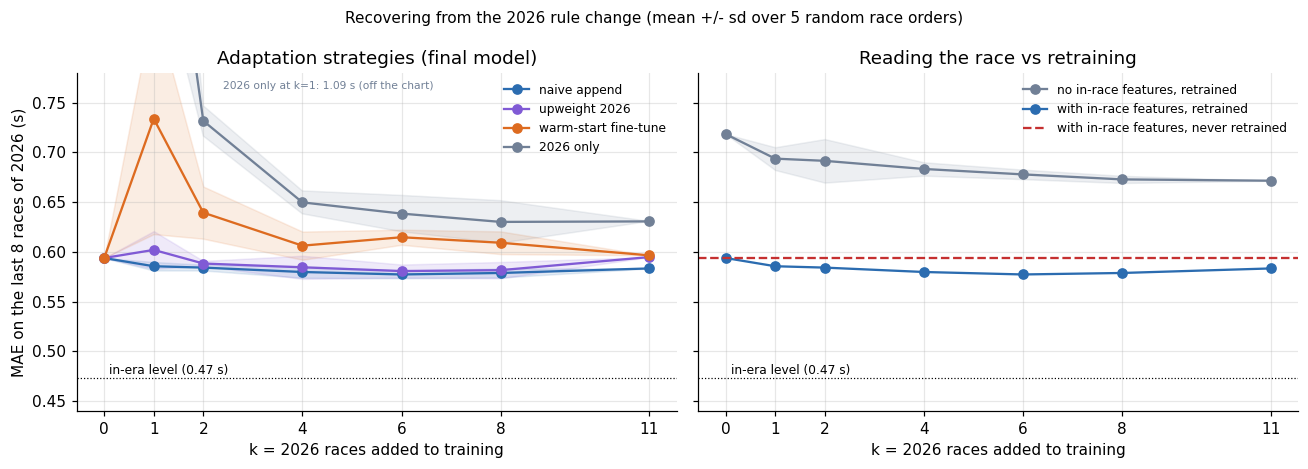

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
colors = {'naive append': '#2b6cb0', 'upweight 2026': '#805ad5', 'warm-start fine-tune': '#dd6b20', '2026 only': '#718096'}
for s in STRATEGIES:
    g = rand[rand.strategy == s].dropna()
    axs[0].plot(g.k, g['mean'], marker='o', color=colors[s], label=s)
    axs[0].fill_between(g.k, g['mean'] - g['std'], g['mean'] + g['std'], color=colors[s], alpha=.12)
axs[0].set_title('Adaptation strategies (final model)'); axs[0].legend(frameon=False, fontsize=8)
nrr = nr[nr.order != 'calendar'].groupby('k').MAE.agg(['mean', 'std'])
wr = rand[rand.strategy == 'naive append'].set_index('k')
axs[1].plot(nrr.index, nrr['mean'], marker='o', color='#718096', label='no in-race features, retrained')
axs[1].fill_between(nrr.index, nrr['mean'] - nrr['std'], nrr['mean'] + nrr['std'], color='#718096', alpha=.12)
axs[1].plot(wr.index, wr['mean'], marker='o', color='#2b6cb0', label='with in-race features, retrained')
axs[1].axhline(cmp.iloc[0, 2], color='#c53030', ls='--', label='with in-race features, never retrained')
axs[1].set_title('Reading the race vs retraining'); axs[1].legend(frameon=False, fontsize=8)
for ax in axs:
    ax.axhline(INERA, color='black', lw=.8, ls=':'); ax.text(0.1, INERA + .005, f'in-era level ({INERA:.2f} s)', fontsize=8)
    ax.set_xlabel('k = 2026 races added to training'); ax.set_xticks(K); ax.grid(alpha=.3)
axs[0].set_ylabel('MAE on the last 8 races of 2026 (s)'); axs[0].set_ylim(0.44, 0.78)
axs[0].text(2.4, 0.772, '2026 only at k=1: %.2f s (off the chart)' % rand[(rand.strategy == '2026 only') & (rand.k == 1)]['mean'].iloc[0],
            fontsize=7, color=colors['2026 only'], va='top')
fig.suptitle('Recovering from the 2026 rule change (mean +/- sd over 5 random race orders)', fontsize=10)
plt.tight_layout(); plt.savefig('figures/06_adaptation.png', dpi=150); plt.show()

**Figure 06.** Three findings, and they change how we answer our research question:
1. **Once the model measures pace, retraining barely matters.** Adding up to 11 races of 2026 data with the best strategy (naive append) improves the late-season error by only ~2-3% (0.594 -> ~0.58 s). In our first iteration, which only knew team names, the first 2026 race was the big win; now qualifying and in-race features deliver most of what that race used to teach the model before it's ever retrained.
2. **The clever strategies do worse than the simple one.** Upweighting 2026 is no better than naive appending. Warm-start fine-tuning on one or two races actively *hurts* (0.73 s at k=1 on average), because 300 trees fit to a single race mostly learn that circuit's quirks. Training on 2026 alone is far worse until it has ~8 races and never catches up. So four seasons of old-regulation data are still valuable in 2026, as long as the features tell the model what changed. (The 300-tree rule was fixed in advance; fewer trees would probably hurt less, but picking that number on the test races would be leakage.)
3. **Reading the race beats retraining.** A model without in-race features starts at 0.72 s and, even retrained with 11 races of 2026, only gets to ~0.67 s. The model *with* in-race features, never retrained at all, sits at 0.59 s from the very first race. Recent laps are a better few-shot signal than whole races of retraining, because they're measured in the current conditions of the current race.

Calendar order and random order tell the same story, so it doesn't hinge on which circuits came first. Note the late-season test races are a bit easier than 2026 overall (0.59 vs 0.63 s at k=0), which is why every curve here sits below the full-season number from notebook 05.

None of the strategies gets anywhere near the in-era level (0.47 s). That remaining gap is the lap-to-lap dynamics that notebook 05 isolated, and more data described by the same features can't teach it. So our answer to *"how many 2026 races does the model need to recover?"* is: **with measurement features, most of the recoverable error is recovered before a single 2026 race is added to training, extra races buy ~2%, and closing the rest of the gap needs new information rather than more of the same.**